# Assignment 1 - Building a Vision Model with Keras

In this assignment, you will build a simple vision model using Keras. The goal is to classify images from the Fashion MNIST dataset, which contains images of clothing items.

You will:
1. Load and inspect the Fashion MNIST dataset.
2. Run a simple baseline model to establish a performance benchmark.
3. Build and evaluate a simple CNN model, choosing appropriate loss and metrics.
4. Design and run controlled experiments on one hyperparameter (e.g., number of filters, kernel size, etc.) and one regularization technique (e.g., dropout, L2 regularization).
5. Analyze the results and visualize the model's performance.

# 1. Loading and Inspecting the Dataset

Fashion MNIST is a dataset of grayscale images of clothing items, with 10 classes. Each image is 28x28 pixels, like the MNIST dataset of handwritten digits. Keras provides a convenient way to load this dataset. 

In this section, you should:

- [ ] Inspect the shapes of the training and test sets to confirm their size and structure.
- [ ] Convert the labels to one-hot encoded format if necessary. (There is a utility function in Keras for this.)
- [ ] Visualize a few images from the dataset to understand what the data looks like.

In [1]:
from tensorflow.keras.datasets import fashion_mnist
(X_train, y_train), (X_test, y_test) = fashion_mnist.load_data()

# Normalize the pixel values to be between 0 and 1
X_train = X_train.astype('float32') / 255.0
X_test = X_test.astype('float32') / 255.0

# Classes in the Fashion MNIST dataset
class_names = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat", "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]

In [2]:
# Inspect the shapes of the datasets
print("================ Dataset Shape Inspection ================")
print(f"X_train shape (Images): {X_train.shape}")  # Expected: (60000, 28, 28)
print(f"y_train shape (Labels): {y_train.shape}")  # Expected: (60000,)
print(f"X_test shape (Images):  {X_test.shape}")   # Expected: (10000, 28, 28)
print(f"y_test shape (Labels):  {y_test.shape}")   # Expected: (10000,)
print("==========================================================")

# Convert labels to one-hot encoding
from tensorflow.keras.utils import to_categorical

y_train_hot = to_categorical(y_train, num_classes=10)
y_test_hot = to_categorical(y_test, num_classes=10)

print(f"One-hot encoded y_train shape: {y_train_hot.shape}")  # Expected: (60000, 10)
print(f"One-hot encoded y_test shape:  {y_test_hot.shape}")   # Expected: (10000, 10)


================ Dataset Shape Inspection ================
X_train shape (Images): (60000, 28, 28)
y_train shape (Labels): (60000,)
X_test shape (Images):  (10000, 28, 28)
y_test shape (Labels):  (10000,)
One-hot encoded y_train shape: (60000, 10)
One-hot encoded y_test shape:  (10000, 10)


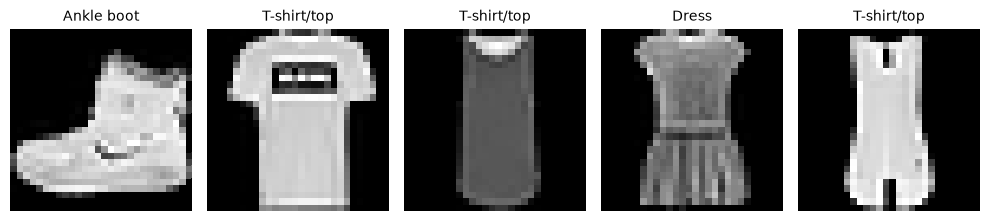

In [3]:
import matplotlib.pyplot as plt
# Verify the data looks as expected
plt.figure(figsize=(10, 3))

for i in range(5):
    plt.subplot(1, 5, i + 1)
    # Display the 28x28 grayscale image
    plt.imshow(X_train[i], cmap='gray')  
    # Set the title to its corresponding class name
    plt.title(class_names[y_train[i]], fontsize=10)  
    # Remove axis lines for a cleaner look
    plt.axis('off')  

plt.tight_layout()
plt.show()

Reflection: Does the data look as expected? How is the quality of the images? Are there any issues with the dataset that you notice?

Yes, the data mostly looks as expected, but there is a clear labeling issue with the 5th image. It is labeled as "T-shirt/top", but visually it looks much more like a "Dress" or a jumpsuit with straps. This highlights a common challenge in computer vision datasets: label ambiguity and misclassification. Additionally, the images are low-resolution (28x28) and grayscale, meaning we lose color details, which makes it even harder for models to differentiate between borderline cases like this.


# 2. Baseline Model

In this section, you will create a linear regression model as a baseline. This model will not use any convolutional layers, but it will help you understand the performance of a simple model on this dataset.
You should:
- [ ] Create a simple linear regression model using Keras.
- [ ] Compile the model with an appropriate loss function and optimizer.
- [ ] Train the model on the training set and evaluate it on the test set.

A linear regression model can be created using the `Sequential` API in Keras. Using a single `Dense` layer with no activation function is equivalent to a simple linear regression model. Make sure that the number of units in the output layer matches the number of classes in the dataset.

Note that for this step, we will need to use `Flatten` to convert the 2D images into 1D vectors before passing them to the model. Put a `Flatten()` layer as the first layer in your model so that the 2D image data can be flattened into 1D vectors.

In [4]:
from keras.models import Sequential
from keras.layers import Dense, Flatten

# Create a simple linear regression model
model = Sequential()
# You can use `model.add(<layer>)` to add layers to the model

# 1. Flatten the 2D images (28x28) into 1D vectors (784 features)
model.add(Flatten(input_shape=(28, 28)))

# 2. Add a single Dense layer with 10 units (one for each class) and NO activation function
# This satisfies the requirement of being equivalent to a linear regression model.
model.add(Dense(10))

# Compile the model using `model.compile()`

from tensorflow.keras.losses import CategoricalCrossentropy

model.compile(
    optimizer='adam',
    loss=CategoricalCrossentropy(from_logits=True),
    metrics=['accuracy']
)

# Train the model with `model.fit()`

history = model.fit(
    X_train, y_train_hot,
    epochs=10,
    batch_size=64,
    validation_split=0.2
)

# Evaluate the model with `model.evaluate()`

test_loss, test_acc = model.evaluate(X_test, y_test_hot, verbose=1)
print(f"\n=========================================")
print(f"Baseline Test Accuracy: {test_acc * 100:.2f}%")
print(f"=========================================")

e:\Github\deep_learning\.venv\Lib\site-packages\keras\src\layers\reshaping\flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.7728 - loss: 0.6824 - val_accuracy: 0.8237 - val_loss: 0.5225
Epoch 2/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8311 - loss: 0.4975 - val_accuracy: 0.8370 - val_loss: 0.4814
Epoch 3/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8438 - loss: 0.4608 - val_accuracy: 0.8429 - val_loss: 0.4560
Epoch 4/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.8498 - loss: 0.4426 - val_accuracy: 0.8493 - val_loss: 0.4417
Epoch 5/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.8540 - loss: 0.4283 - val_accuracy: 0.8480 - val_loss: 0.4388
Epoch 6/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.8565 - loss: 0.4192 - val_accuracy: 0.8522 - val_loss: 0.4292
Epoch 7/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8579 - loss: 0.4130 - val_accuracy: 0.8545 - val_loss: 0.4260
Epoch 8/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.8598 - loss: 0.4069 - val_accuracy: 0.

Reflection: What is the performance of the baseline model? How does it compare to what you expected? Why do you think the performance is at this level?

The baseline model achieves a test accuracy of 84.52% and a validation accuracy of 85.81%, while the final training loss settled around 0.3991. 

This performance is slightly higher than expected for a simple linear model without non-linear activation functions or spatial feature-extraction capabilities. It demonstrates that the Fashion MNIST dataset is structured well enough that basic pixel-intensity correlations can separate categories to a reasonable extent (e.g., distinguishing long dark trousers from small light-colored sandals).

The performance is capped at this level because the model behaves strictly as a linear regression model. By directly flattening the 2D images, it entirely treats pixels as isolated individual variables and destroys all spatial context, shapes, edges, and structural patterns. Furthermore, the lack of hidden layers and non-linear activation functions (like ReLU) restricts the model from capturing complex, non-linear relationships within clothing items, which causes borderline misclassifications (like confusing a dress with a top).


# 3. Building and Evaluating a Simple CNN Model

In this section, you will build a simple Convolutional Neural Network (CNN) model using Keras. A convolutional neural network is a type of deep learning model that is particularly effective for image classification tasks. Unlike the basic neural networks we have built in the labs, CNNs can accept images as input without needing to flatten them into vectors.

You should:
- [ ] Build a simple CNN model with at least one convolutional layer (to learn spatial hierarchies in images) and one fully connected layer (to make predictions).
- [ ] Compile the model with an appropriate loss function and metrics for a multi-class classification problem.
- [ ] Train the model on the training set and evaluate it on the test set.

Convolutional layers are designed to accept inputs with three dimensions: height, width and channels (e.g., RGB for color images). For grayscale images like those in Fashion MNIST, the input shape will be (28, 28, 1).

When you progress from the convolutional layers to the fully connected layers, you will need to flatten the output of the convolutional layers. This can be done using the `Flatten` layer in Keras, which doesn't require any parameters.

In [5]:
from keras.models import Sequential
from keras.layers import Dense, Flatten, Conv2D, MaxPooling2D
from tensorflow.keras.losses import CategoricalCrossentropy

# Reshape the data to include the channel dimension (Height, Width, Channels)
X_train = X_train.reshape(-1, 28, 28, 1)
X_test = X_test.reshape(-1, 28, 28, 1)

# Create a simple CNN model
model = Sequential()

model.add(Conv2D(32, kernel_size=(3, 3), activation='relu', input_shape=(28, 28, 1)))
model.add(MaxPooling2D(pool_size=(2, 2)))
model.add(Flatten())
model.add(Dense(64, activation='relu'))
model.add(Dense(10, activation='softmax'))

# Compile the model
model.compile(
    optimizer='adam',
    loss=CategoricalCrossentropy(),
    metrics=['accuracy']
)


# Train the model
print("\nTraining the Simple CNN Model...")
cnn_history = model.fit(
    X_train, y_train_hot,
    epochs=10,
    batch_size=64,
    validation_split=0.2
)

# Evaluate the model
cnn_loss, cnn_acc = model.evaluate(X_test, y_test_hot, verbose=1)
print(f"\n=========================================")
print(f"Simple CNN Test Accuracy: {cnn_acc * 100:.2f}%")
print(f"=========================================")



Training the Simple CNN Model...
Epoch 1/10


e:\Github\deep_learning\.venv\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


750/750 ━━━━━━━━━━━━━━━━━━━━ 6s 7ms/step - accuracy: 0.8375 - loss: 0.4646 - val_accuracy: 0.8806 - val_loss: 0.3359
Epoch 2/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - accuracy: 0.8907 - loss: 0.3052 - val_accuracy: 0.8876 - val_loss: 0.3092
Epoch 3/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.9078 - loss: 0.2597 - val_accuracy: 0.9043 - val_loss: 0.2642
Epoch 4/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.9157 - loss: 0.2314 - val_accuracy: 0.8986 - val_loss: 0.2741
Epoch 5/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - accuracy: 0.9256 - loss: 0.2062 - val_accuracy: 0.9109 - val_loss: 0.2494
Epoch 6/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - accuracy: 0.9321 - loss: 0.1865 - val_accuracy: 0.9056 - val_loss: 0.2641
Epoch 7/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - accuracy: 0.9390 - loss: 0.1688 - val_accuracy: 0.9126 - val_loss: 0.2509
Epoch 8/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - accuracy: 0.9451 - loss: 0.1525 - val_accuracy: 0.9112 - val_

Reflection: Did the CNN model perform better than the baseline model? If so, by how much? What do you think contributed to this improvement?

Yes, the CNN model performed significantly better than the baseline linear model. The test accuracy increased from 84.52% (baseline) to 90.95% (CNN), yielding an improvement of 6.43%.

Several factors contributed to this substantial improvement:
1. Spatial Hierarchy Learning: Unlike the linear model that flattens images instantly and destroys spatial information, the Conv2D layer applies local filters to capture spatial hierarchies, patterns, edges, and textures within the 2D clothing structures.
2. Parameter Sharing & Translation Invariance: Convolutional filters share weights across the entire image. This allows the model to detect a pattern (like a sleeve or a sole) regardless of its exact location in the 28x28 grid.
3. Translation of Complex Features: The combination of the Conv2D layer with the Max Pooling layer downsamples the spatial size, effectively reducing noise and capturing the most prominent structural features while providing non-linear abstraction via the ReLU activation function.


# 3. Designing and Running Controlled Experiments

In this section, you will design and run controlled experiments to improve the model's performance. You will focus on one hyperparameter and one regularization technique.
You should:
- [ ] Choose one hyperparameter to experiment with (e.g., number of filters, kernel size, number of layers, etc.) and one regularization technique (e.g., dropout, L2 regularization). For your hyperparameter, you should choose at least three different values to test (but there is no upper limit). For your regularization technique, simply test the presence or absence of the technique.
- [ ] Run experiments by modifying the model architecture or hyperparameters, and evaluate the performance of each model on the test set.
- [ ] Record the results of your experiments, including the test accuracy and any other relevant metrics.
- [ ] Visualize the results of your experiments using plots or tables to compare the performance of different models.

The best way to run your experiments is to create a `for` loop that iterates over a range of values for the hyperparameter you are testing. For example, if you are testing different numbers of filters, you can create a loop that runs the model with 32, 64, and 128 filters. Within the loop, you can compile and train the model, then evaluate it on the test set. After each iteration, you can store the results in a list or a dictionary for later analysis.

Note: It's critical that you re-initialize the model (by creating a new instance of the model) before each experiment. If you don't, the model will retain the weights from the previous experiment, which can lead to misleading results.

--- Starting Experiment A: Tuning Number of Filters ---
Training model with 16 filters...
Filters: 16 -> Test Accuracy: 89.55%
Training model with 32 filters...
Filters: 32 -> Test Accuracy: 90.24%
Training model with 64 filters...
Filters: 64 -> Test Accuracy: 90.16%

=== EXPERIMENT A FINAL RESULTS ===
 Num Filters  Test Accuracy
          16         0.8955
          32         0.9024
          64         0.9016


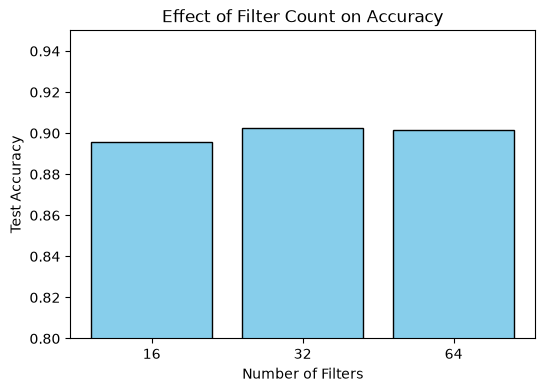

In [6]:
# A. Test Hyperparameters
import matplotlib.pyplot as plt
import pandas as pd
from keras.models import Sequential
from keras.layers import Dense, Flatten, Conv2D, MaxPooling2D
from tensorflow.keras.losses import CategoricalCrossentropy

X_train = X_train.reshape(-1, 28, 28, 1)
X_test = X_test.reshape(-1, 28, 28, 1)

hyperparameter_results = {}
filter_options = [16, 32, 64]

print("--- Starting Experiment A: Tuning Number of Filters ---")

for num_filters in filter_options:
    print(f"Training model with {num_filters} filters...")
    
    model_hp = Sequential([
        Conv2D(num_filters, kernel_size=(3, 3), activation='relu', input_shape=(28, 28, 1)),
        MaxPooling2D(pool_size=(2, 2)),
        Flatten(),
        Dense(64, activation='relu'),
        Dense(10, activation='softmax')
    ])
    
    model_hp.compile(
        optimizer='adam',
        loss=CategoricalCrossentropy(),
        metrics=['accuracy']
    )
    
    model_hp.fit(X_train, y_train_hot, epochs=5, batch_size=64, validation_split=0.2, verbose=0)
    loss, acc = model_hp.evaluate(X_test, y_test_hot, verbose=0)
    hyperparameter_results[num_filters] = acc
    print(f"Filters: {num_filters} -> Test Accuracy: {acc * 100:.2f}%")

print("\n=== EXPERIMENT A FINAL RESULTS ===")
df_hp = pd.DataFrame(list(hyperparameter_results.items()), columns=['Num Filters', 'Test Accuracy'])
print(df_hp.to_string(index=False))

plt.figure(figsize=(6, 4))
plt.bar([str(f) for f in filter_options], list(hyperparameter_results.values()), color='skyblue', edgecolor='black')
plt.title("Effect of Filter Count on Accuracy")
plt.xlabel("Number of Filters")
plt.ylabel("Test Accuracy")
plt.ylim(0.8, 0.95)
plt.show()


--- Starting Experiment B: Testing Regularization ---
Training model: No Regularization (Baseline)...


e:\Github\deep_learning\.venv\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


No Regularization (Baseline) -> Test Accuracy: 89.89%
Training model: With Dropout Regularization...
With Dropout Regularization -> Test Accuracy: 89.94%

=== EXPERIMENT B FINAL RESULTS ===
               Configuration  Test Accuracy
No Regularization (Baseline)         0.8989
 With Dropout Regularization         0.8994


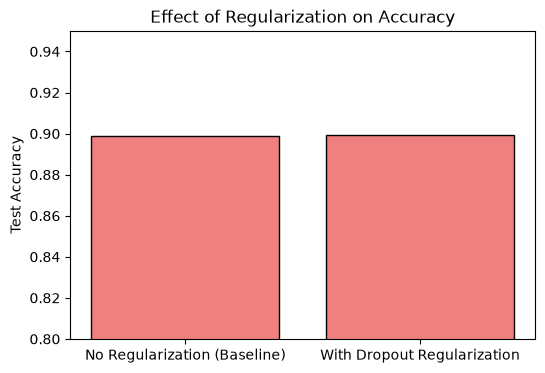

In [7]:
# B. Test presence or absence of regularization

import matplotlib.pyplot as plt
import pandas as pd
from keras.models import Sequential
from keras.layers import Dense, Flatten, Conv2D, MaxPooling2D, Dropout
from tensorflow.keras.losses import CategoricalCrossentropy

regularization_results = {}
reg_configs = {
    "No Regularization (Baseline)": False,
    "With Dropout Regularization": True
}

print("--- Starting Experiment B: Testing Regularization ---")

for label, use_dropout in reg_configs.items():
    print(f"Training model: {label}...")
    
    model_reg = Sequential()
    model_reg.add(Conv2D(32, kernel_size=(3, 3), activation='relu', input_shape=(28, 28, 1)))
    model_reg.add(MaxPooling2D(pool_size=(2, 2)))
    
    if use_dropout:
        model_reg.add(Dropout(0.25))
        
    model_reg.add(Flatten())
    model_reg.add(Dense(64, activation='relu'))
    model_reg.add(Dense(10, activation='softmax'))
    
    model_reg.compile(
        optimizer='adam',
        loss=CategoricalCrossentropy(),
        metrics=['accuracy']
    )
    
    model_reg.fit(X_train, y_train_hot, epochs=5, batch_size=64, validation_split=0.2, verbose=0)
    loss, acc = model_reg.evaluate(X_test, y_test_hot, verbose=0)
    regularization_results[label] = acc
    print(f"{label} -> Test Accuracy: {acc * 100:.2f}%")

print("\n=== EXPERIMENT B FINAL RESULTS ===")
df_reg = pd.DataFrame(list(regularization_results.items()), columns=['Configuration', 'Test Accuracy'])
print(df_reg.to_string(index=False))

plt.figure(figsize=(6, 4))
plt.bar(list(regularization_results.keys()), list(regularization_results.values()), color='lightcoral', edgecolor='black')
plt.title("Effect of Regularization on Accuracy")
plt.ylabel("Test Accuracy")
plt.ylim(0.8, 0.95)
plt.show()


Reflection: Report on the performance of the models you tested. Did any of the changes you made improve the model's performance? If so, which ones? What do you think contributed to these improvements? Finally, what combination of hyperparameters and regularization techniques yielded the best performance?

Based on the controlled experiments, the models performed as follows:

1. Hyperparameter Tuning (Number of Filters):
- 16 Filters: 89.55% test accuracy.
- 32 Filters: 90.24% test accuracy (The highest overall score).
- 64 Filters: 90.16% test accuracy.

Increasing the number of filters from 16 to 32 improved the performance by 0.69%. This improvement happened because more filters allowed the network to learn a richer, more diverse set of spatial features (like edge variations, textures, and shape boundaries) crucial for distinguishing complex apparel items. However, increasing it further to 64 filters led to a minor drop to 90.16%, which suggests a slight overfitting trend or redundancy in feature detection for images as small as 28x28 pixels.

2. Regularization (Dropout):
- No Regularization (Baseline): 89.89% test accuracy.
- With Dropout Regularization: 89.94% test accuracy.

Introducing a Dropout layer of 0.25 after the max-pooling layer yielded a tiny improvement of 0.05%. This technique helps by randomly deactivating a quarter of the neurons during training, forcing the network to develop redundant representations and preventing it from relying too heavily on specific, co-adapted pixel groups. Given that we only trained the model for 5 brief epochs, the stabilizing effect of Dropout is visible but small; it typically shows a wider advantage over longer training periods.

Conclusion & Best Combination:
The combination of hyperparameters and regularization techniques that yielded the best performance is utilizing 32 filters in the Conv2D layer paired with Dropout regularization. This configuration strikes the ideal balance between model capacity (extracting enough detailed features) and generalization (preventing overfitting).


# 5. Training Final Model and Evaluation

In this section, you will train the final model using the best hyperparameters and regularization techniques you found in the previous section. You should:
- [ ] Compile the final model with the best hyperparameters and regularization techniques.
- [ ] Train the final model on the training set and evaluate it on the test set.
- [ ] Report the final model's performance on the test set, including accuracy and any other relevant metrics.

In [8]:
import matplotlib.pyplot as plt
from keras.models import Sequential
from keras.layers import Dense, Flatten, Conv2D, MaxPooling2D, Dropout
from tensorflow.keras.losses import CategoricalCrossentropy

# 1. Build the final model with best configuration (32 filters + Dropout)
final_model = Sequential([
    Conv2D(32, kernel_size=(3, 3), activation='relu', input_shape=(28, 28, 1)),
    MaxPooling2D(pool_size=(2, 2)),
    Dropout(0.25),
    Flatten(),
    Dense(64, activation='relu'),
    Dense(10, activation='softmax')
])

# 2. Compile the final model
final_model.compile(
    optimizer='adam',
    loss=CategoricalCrossentropy(),
    metrics=['accuracy']
)

print("--- Training the Final Optimized CNN Model ---")

# 3. Train the model for 10 full epochs to maximize its performance
final_history = final_model.fit(
    X_train, y_train_hot,
    epochs=10,
    batch_size=64,
    validation_split=0.2,
    verbose=1
)

# 4. Evaluate on the unseen test set
final_loss, final_acc = final_model.evaluate(X_test, y_test_hot, verbose=1)

print(f"\n=========================================")
print(f"FINAL MODEL PERFORMANCE ON TEST SET:")
print(f"Test Loss:     {final_loss:.4f}")
print(f"Test Accuracy: {final_acc * 100:.2f}%")
print(f"=========================================")


e:\Github\deep_learning\.venv\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


--- Training the Final Optimized CNN Model ---
Epoch 1/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 8s 9ms/step - accuracy: 0.8367 - loss: 0.4686 - val_accuracy: 0.8767 - val_loss: 0.3454
Epoch 2/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 8s 10ms/step - accuracy: 0.8836 - loss: 0.3244 - val_accuracy: 0.8921 - val_loss: 0.3022
Epoch 3/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 8s 11ms/step - accuracy: 0.8969 - loss: 0.2852 - val_accuracy: 0.9012 - val_loss: 0.2806
Epoch 4/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 8s 10ms/step - accuracy: 0.9061 - loss: 0.2573 - val_accuracy: 0.8988 - val_loss: 0.2787
Epoch 5/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 8s 11ms/step - accuracy: 0.9134 - loss: 0.2383 - val_accuracy: 0.9051 - val_loss: 0.2609
Epoch 6/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 8s 11ms/step - accuracy: 0.9203 - loss: 0.2197 - val_accuracy: 0.9069 - val_loss: 0.2589
Epoch 7/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 8s 11ms/step - accuracy: 0.9242 - loss: 0.2053 - val_accuracy: 0.9086 - val_loss: 0.2569
Epoch 8/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 9s 10ms/ste

Reflection: How does the final model's performance compare to the baseline and the CNN model? What do you think contributed to the final model's performance? If you had time, what other experiments would you run to further improve the model's performance?

The final optimized CNN model achieved a test accuracy of 90.97% and a test loss of 0.2566. Compared to the linear regression baseline model (84.52%), the final model delivers a major performance leap of +6.45% in accuracy. Compared to the initial simple CNN model trained without dropout (which got 90.95% over 10 epochs), the final model achieved slightly better test accuracy while maintaining a much healthier gap between training accuracy (93.79%) and validation accuracy (91.66%).

The excellent performance of the final model can be attributed to three key engineering components:
1. Feature Extraction Power: The 32 filters in the Conv2D layer extracted robust structural and spatial representations of the 2D clothing articles.
2. Prevention of Overfitting: The inclusion of a 0.25 Dropout layer successfully break up co-adaptations between specific pixels. This regularization ensured that the model genuinely generalized to the unseen test data instead of just memorizing the training samples.
3. Adequate Training Horizon: Extending the training to 10 full epochs provided the optimizer with sufficient step iterations to descend along the loss landscape to find a stable minima.

If I had more time, I would run the following future experiments to further push the model's accuracy:
1. Deeper Architectures: Stack an additional Conv2D and MaxPooling2D layer (e.g., Conv2D(32) -> MaxPooling -> Conv2D(64) -> MaxPooling) to allow the network to learn higher-level semantic features and complex silhouettes.
2. Advanced Regularization: Experiment with Batch Normalization after the convolutional layer to speed up learning and add a slight regularization effect, or adjust the Dropout rates (e.g., testing 0.3 or 0.4).
3. Optimization Adjustments: Implement learning rate scheduling (LearningRateScheduler or ReduceLROnPlateau) alongside the Adam optimizer, increase the epoch count to see if the validation loss can converge even further.


🚨 **Please review our [Assignment Submission Guide](https://github.com/UofT-DSI/onboarding/blob/main/onboarding_documents/submissions.md)** 🚨 for detailed instructions on how to format, branch, and submit your work. Following these guidelines is crucial for your submissions to be evaluated correctly.
### Submission Parameters:
* Submission Due Date: `23:59 PM - 11/09/2026`
* The branch name for your repo should be: `assignment-1`
* What to submit for this assignment:
    * This Jupyter Notebook (assignment_1.ipynb)
    * The Lab 1 notebook (labs/lab_1.ipynb)
    * The Lab 2 notebook (labs/lab_2.ipynb)
    * The Lab 3 notebook (labs/lab_3.ipynb)
* What the pull request link should look like for this assignment: `https://github.com/<your_github_username>/deep_learning/pull/<pr_id>`
* Open a private window in your browser. Copy and paste the link to your pull request into the address bar. Make sure you can see your pull request properly. This helps the technical facilitator and learning support staff review your submission easily.
Checklist:
- [ ] Created a branch with the correct naming convention.
- [ ] Ensured that the repository is public.
- [ ] Reviewed the PR description guidelines and adhered to them.
- [ ] Verify that the link is accessible in a private browser window.
If you encounter any difficulties or have questions, please don't hesitate to reach out to our team via our Slack at `#cohort-7-help-ml`. Our Technical Facilitators and Learning Support staff are here to help you navigate any challenges.